In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.DataFrame({
    "soil_moisture": [0.10, 0.15, 0.20, 0.25, 0.40, 0.60, 0.35, 0.18,
                      0.45, 0.05, 0.80, 0.27, 0.55, 0.70, 0.12, 0.30],
    "temperature_c": [34, 30, 26, 22, 28, 30, 19, 22,
                      35, 24, 33, 33, 21, 25, 20, 29],
    "sunlight_hours": [9, 8, 7, 4, 8, 10, 3, 10,
                       12, 5, 9, 11, 2, 6, 1, 9],
    "needs_water": [1, 1, 1, 0, 0, 0, 0, 1,
                    0, 1, 0, 1, 0, 0, 1, 1]
})

In [3]:
df  ## for deep learning project you need big data by using tgis data we bulid a basic project

,soil_moisture,temperature_c,sunlight_hours,needs_water
0,0.10,34,9,1
1,0.15,30,8,1
2,0.20,26,7,1
3,0.25,22,4,0
4,0.40,28,8,0
5,0.60,30,10,0
6,0.35,19,3,0
7,0.18,22,10,1
8,0.45,35,12,0
9,0.05,24,5,1


In [4]:
df.columns


Index(['soil_moisture', 'temperature_c', 'sunlight_hours', 'needs_water'], dtype='object')

In [5]:
X = df[['soil_moisture', 'temperature_c', 'sunlight_hours']]
y = df['needs_water']

In [6]:
## now we have to train test split but before the train test split we have to normalize/standrize the data value for better preddication
## for deep learing we used normalization (min max scaler)

In [7]:
X_max = X.max()
X_min = X.min()
X_scaled = (X - X_min) / (X_max - X_min)

In [8]:
X_scaled

,soil_moisture,temperature_c,sunlight_hours
0,0.066667,0.9375,0.727273
1,0.133333,0.6875,0.636364
2,0.200000,0.4375,0.545455
3,0.266667,0.1875,0.272727
4,0.466667,0.5625,0.636364
5,0.733333,0.6875,0.818182
6,0.400000,0.0000,0.181818
7,0.173333,0.1875,0.818182
8,0.533333,1.0000,1.000000
9,0.000000,0.3125,0.363636


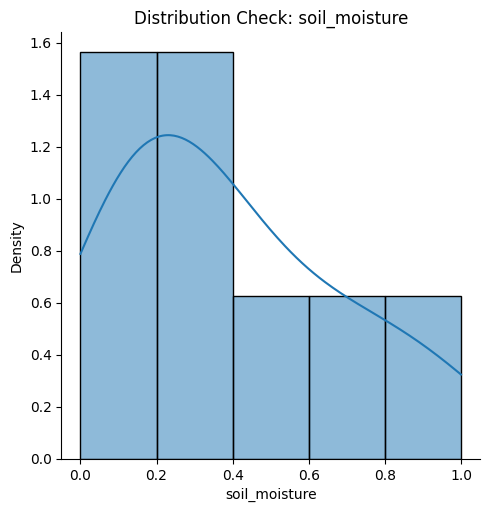

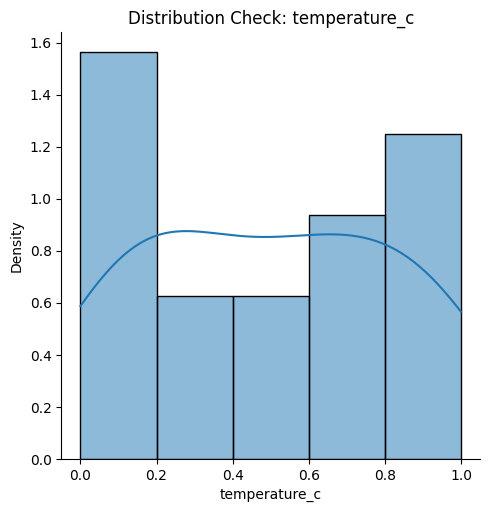

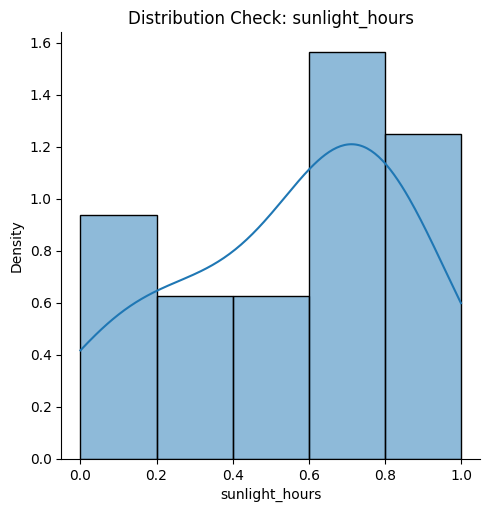

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
def checkDistribution(X, col_name):
    sns.displot(data=X, x=col_name, kde=True, stat="density")
    plt.title(f"Distribution Check: {col_name}")
    plt.show()

for i in range(len(X_scaled.columns)):
    col_name = X_scaled.columns[i]
    checkDistribution(X_scaled, col_name)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y, test_size=0.20, random_state=42,stratify=y)

In [11]:
print(X_train.shape)
print(f"Colum no is {X_train.shape[1]}")

(12, 3)
Colum no is 3


In [12]:
model = keras.Sequential([
    layers.Input(shape = (X_train.shape[1],)),
    layers.Dense(8, activation = 'relu'),
    layers.Dense(1, activation = 'sigmoid')
])

In [13]:
model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

In [14]:
history = model.fit(X_train.values,y_train.values,
                    validation_data = (X_test.values,y_test.values),
                    epochs = 100,
                    batch_size = 4,  ## small data
                    verbose = 1   # 0 means we can,t see the epochs
                    )

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 172ms/step - accuracy: 0.3333 - loss: 0.7267 - val_accuracy: 0.5000 - val_loss: 0.7286
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.3333 - loss: 0.7255 - val_accuracy: 0.5000 - val_loss: 0.7277
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.3333 - loss: 0.7250 - val_accuracy: 0.5000 - val_loss: 0.7269
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3333 - loss: 0.7237 - val_accuracy: 0.5000 - val_loss: 0.7261
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.3333 - loss: 0.7228 - val_accuracy: 0.5000 - val_loss: 0.7253
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.4167 - loss: 0.7227 - val_accuracy: 0.5000 - val_loss: 0.7244
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4167 - loss: 0.7197 - val_accuracy: 0.5000 - val_loss: 0.7236
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3333 - loss: 0.7189 - val_accuracy: 0.5000 - val_loss